# Train a PDE reconstruction model
Run setup, review the preview, then explicitly set **`RUN_MODE="train"` in Start training**. Saved Run All starts zero optimizer updates. Select A, B0, B1 or C; D is evaluation-only. No other notebook is required.

**Fresh Colab:** open this notebook directly from your GitHub repository, choose a GPU runtime, configure the repository below, then run setup. Setup verifies/clones and installs the checkout, validates CUDA and optionally mounts Drive. Local CPU/MPS uses the installed project and local outputs, ignoring Colab-only settings. Private Git authentication must be configured outside the notebook using a credential helper or SSH agent; never embed secrets in URLs, cells or outputs.


In [1]:
# Setup configuration — used only in Colab. Local sessions need an installed project.
REPO_URL = "SET_YOUR_GITHUB_REPOSITORY_URL"
REPO_REF = "main"  # Prefer an immutable full commit SHA or release tag for research.
PROJECT_DIR = "/content/pde-inverse-research"

USE_GOOGLE_DRIVE = False
DRIVE_ROOT = "/content/drive/MyDrive/PDEInverseResearch"
LOCAL_OUTPUT_DIR = "/content/pde-inverse-outputs"


In [2]:
# Automatic setup — advanced implementation (collapsed). Run this cell normally.
# Stdlib bootstrap is embedded because pdeep is absent in a fresh Colab runtime.
import sys, json
from pathlib import Path
try:
    from IPython import get_ipython
    _shell = get_ipython()
except ImportError:
    _shell = None
IS_COLAB = "google.colab" in sys.modules or type(_shell).__module__.startswith("google.colab")

def ensure_checkout(repo_url, repo_ref, project_dir, *, git_env=None):
    """Clone only absent destinations; existing worktrees are strictly read-only.

    Supports token-free HTTPS and Git-over-SSH URLs. External credential helpers
    or SSH agents handle private authentication. Raw Git output stays in memory.
    """
    import os, re, subprocess, tempfile
    from pathlib import Path
    from urllib.parse import urlsplit
    import sys
    if sys.version_info < (3, 10):
        raise RuntimeError('PDEep requires Python >=3.10; select a supported runtime before setup.')
    def identity(value):
        if not isinstance(value,str) or not value or any(c in value for c in '\n\r\0'):
            raise ValueError('Configure a token-free repository URL; credentials must not be embedded.')
        if value.startswith('git@'):
            match=re.fullmatch(r'git@([A-Za-z0-9.-]+):([A-Za-z0-9_./-]+)',value)
            if not match:raise ValueError('Use git@HOST:OWNER/REPO.git with an external SSH agent.')
            host,path=match.groups()
        else:
            url=urlsplit(value)
            if url.scheme not in {'https','ssh'} or not url.hostname or url.password or url.query or url.fragment:
                raise ValueError('Use token-free HTTPS or Git SSH; credential URLs, queries and fragments are rejected.')
            if (url.scheme=='https' and url.username is not None) or (url.scheme=='ssh' and url.username not in {None,'git'}):
                raise ValueError('Do not put credentials/user tokens in repository URLs; use an external credential helper or SSH agent.')
            host=url.hostname;path=url.path.lstrip('/')
            if url.port not in {None,22,443}:raise ValueError('Unsupported repository port.')
        path=path.rstrip('/').removesuffix('.git')
        if not path or len(path.split('/'))<2 or '..' in path.split('/'):
            raise ValueError('Configure REPO_URL with OWNER/REPO; no local or credential-bearing URL is accepted.')
        if host.lower()=='github.com':path=path.lower()
        return host.lower()+'/'+path
    expected=identity(repo_url)
    if not isinstance(repo_ref,str) or not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_./-]*',repo_ref) or '..' in repo_ref:
        raise ValueError('REPO_REF must be a branch, tag or full commit SHA, not a command or revision expression.')
    destination=Path(project_dir).expanduser().resolve()
    env=dict(os.environ);env.update(git_env or {});env['GIT_TERMINAL_PROMPT']='0'
    def git(arguments, *, cwd=None, purpose='repository verification'):
        try:result=subprocess.run(['git',*arguments],cwd=cwd,env=env,capture_output=True,text=True,timeout=180)
        except FileNotFoundError:raise RuntimeError('Git is missing; install Git before repository setup.') from None
        except (OSError,subprocess.TimeoutExpired):raise RuntimeError('Git '+purpose+' could not complete; no credentials/output were logged.') from None
        if result.returncode:
            error=result.stderr.lower()
            if any(s in error for s in ('authentication','could not read username','publickey','permission denied')):
                raise RuntimeError('Git authentication failed. Configure an external credential helper or SSH agent with read access; do not put secrets in this notebook.')
            raise RuntimeError('Git '+purpose+' failed. Check repository existence, access and REPO_REF. Raw output is suppressed to protect credentials.')
        return result.stdout.strip()
    def head(path):return git(['rev-parse','--verify','HEAD^{commit}'],cwd=path)
    def resolved_ref(path):
        if re.fullmatch(r'[0-9a-fA-F]{40}|[0-9a-fA-F]{64}',repo_ref):wanted=repo_ref.lower()
        else:
            refs=[repo_ref,repo_ref+'^{}'] if repo_ref.startswith('refs/') else ['refs/heads/'+repo_ref,'refs/tags/'+repo_ref,'refs/tags/'+repo_ref+'^{}']
            lines=git(['ls-remote','--exit-code','origin',*refs],cwd=path,purpose='remote reference lookup')
            mapping=dict((ref,sha) for sha,ref in (line.split() for line in lines.splitlines()))
            if repo_ref.startswith('refs/'):wanted=mapping.get(repo_ref+'^{}',mapping.get(repo_ref))
            else:
                branch=mapping.get('refs/heads/'+repo_ref);tag=mapping.get('refs/tags/'+repo_ref+'^{}',mapping.get('refs/tags/'+repo_ref))
                if branch and tag and branch!=tag:raise ValueError('Branch/tag name is ambiguous; use refs/heads/... or refs/tags/....')
                wanted=branch or tag
            if not wanted:raise ValueError('Configured REPO_REF was not found on origin.')
        return wanted
    existed=destination.exists()
    if existed:
        if not destination.is_dir() or not (destination/'.git').exists():
            raise ValueError('PROJECT_DIR exists but is not a Git checkout; choose a separate empty directory. Nothing was overwritten.')
        top=Path(git(['rev-parse','--show-toplevel'],cwd=destination)).resolve()
        if top!=destination:raise ValueError('PROJECT_DIR must be the repository root, not a nested directory.')
        origin=git(['config','--get','remote.origin.url'],cwd=destination)
        if identity(origin)!=expected:raise ValueError('Existing checkout origin differs from REPO_URL. No files or remotes were changed.')
        if git(['status','--porcelain','--untracked-files=normal'],cwd=destination):
            raise ValueError('Existing checkout has local modifications/untracked files. Commit them yourself or choose a new PROJECT_DIR; no reset/checkout was performed.')
        commit=head(destination)
        wanted=resolved_ref(destination)
        if commit!=wanted:
            raise ValueError('Existing checkout is at '+commit+' but REPO_REF resolves to '+wanted+'. Choose a new PROJECT_DIR or update it explicitly; nothing was reset.')
    else:
        destination.parent.mkdir(parents=True,exist_ok=True)
        # A failed clone stays in its own scratch directory, not PROJECT_DIR.
        with tempfile.TemporaryDirectory(prefix='.pdeep-clone-',dir=destination.parent) as scratch:
            checkout=Path(scratch)/'checkout'
            git(['clone','--no-checkout','--',repo_url,str(checkout)],purpose='clone')
            wanted=resolved_ref(checkout)
            git(['fetch','--depth','1','origin',wanted],cwd=checkout,purpose='configured reference fetch')
            git(['checkout','--detach','FETCH_HEAD'],cwd=checkout,purpose='fresh checkout')
            commit=head(checkout)
            if commit!=wanted:raise RuntimeError('Fetched checkout differs from the resolved reference; setup stopped.')
            required=('pyproject.toml','src/pdeep/__init__.py','src/pdeep/colab_setup.py','docs/scientific_contract_v1.md')
            if any(not (checkout/p).is_file() for p in required):
                raise ValueError('Repository/ref lacks the expected PDEep structure or this Colab setup version; select a compatible commit.')
            os.rename(checkout,destination)
    required=('pyproject.toml','src/pdeep/__init__.py','src/pdeep/colab_setup.py','docs/scientific_contract_v1.md')
    if any(not (destination/p).is_file() for p in required):raise ValueError('Expected pyproject.toml, pdeep package/setup and scientific contract are missing.')
    return {'project_dir':str(destination),'repository_identity':expected,'requested_ref':repo_ref,'git_commit':commit,
            'existing_checkout':existed,'worktree_modified_by_setup':not existed,'credentials_recorded':False}

BOOTSTRAP = None
if IS_COLAB:
    BOOTSTRAP = ensure_checkout(REPO_URL, REPO_REF, PROJECT_DIR)
    # Only load/install code after repository identity and revision verification.
    import runpy
    _setup_module = runpy.run_path(str(Path(BOOTSTRAP["project_dir"]) / "src/pdeep/colab_setup.py"))
    _setup_module["install_checkout"](BOOTSTRAP["project_dir"])
from pdeep.colab_setup import finish_setup
SETUP = finish_setup(is_colab=IS_COLAB, bootstrap=BOOTSTRAP, use_drive=USE_GOOGLE_DRIVE,
    drive_root=DRIVE_ROOT, local_output_dir=LOCAL_OUTPUT_DIR)
SETUP_CONFIGURATION = (REPO_URL, REPO_REF, PROJECT_DIR, USE_GOOGLE_DRIVE, DRIVE_ROOT, LOCAL_OUTPUT_DIR)
ROOT = Path(SETUP["project_dir"])
from IPython.display import display, Markdown
from pdeep.notebook_workflows import initialize
from pdeep.runtime import capabilities
print("Colab:", IS_COLAB, "| imported source:", ROOT / "src/pdeep")
print("Exact Git commit:", SETUP["git_commit"] or "unavailable: local project is not a Git checkout")
print("Python:", SETUP["runtime"]["python"])
print("Dependency versions:", json.dumps(SETUP["runtime"]["dependencies"], indent=2))
for c in capabilities(): print(c.device, "available="+str(c.available), c.detail)
if IS_COLAB: print("Validated CUDA:", SETUP["cuda"])
print("Local checkpoints:", Path(SETUP["local_output_dir"]) / "training_runs")
print("Drive checkpoints:", None if not SETUP["drive_root"] else Path(SETUP["drive_root"]) / "checkpoints")
print(SETUP["message"])


Colab: False | imported source: /Users/nicolasackermann/Documents/ChatGPT/PDEep/src/pdeep
Exact Git commit: bcf76427e542c4f612277f1e83265c8874271e23
Python: 3.12.3 (v3.12.3:f6650f9ad7, Apr  9 2024, 08:18:47) [Clang 13.0.0 (clang-1300.0.29.30)]
Dependency versions: {
  "pdeep-research": "0.1.0",
  "torch": "2.15.0",
  "numpy": "2.5.4",
  "scipy": "1.18.1",
  "matplotlib": "3.11.2",
  "pytest": "9.2.0",
  "notebook": "7.6.5",
  "nbformat": "5.11.1",
  "nbclient": "0.11.0",
  "ipykernel": "7.4.0",
  "setuptools": "84.2.1"
}
cpu available=True arm
mps available=True MPS float64 unsupported; explicit float32 neural execution only
cuda available=False CUDA unavailable
Local checkpoints: /Users/nicolasackermann/Documents/ChatGPT/PDEep/artifacts/training_runs
Drive checkpoints: None
Local session: no clone, install or Google Drive import/mount; local outputs only.


## Configure
Choose model(s), PDEs and budget. For B0 use `MODELS=("B0",)`; for B1 use `MODELS=("B1",)`. `PRESET="smoke", UPDATES=2` checks execution; research uses 10,000 updates. Defaults retain the existing AdamW, losses, batches and fixed validation. On Colab, `DEVICE="auto"` means validated CUDA and never falls back to CPU. Local auto selects CUDA/MPS/CPU.

Resume: set `ACTION="resume"` and select a complete verified checkpoint manifest from Drive. Preview checks architecture/configuration and stages it locally. Saved optimizer/schedule/budget/device are preserved; leave advanced overrides empty.


In [4]:
MODELS = ("C",)
PDE_FAMILIES = ("poisson", "heat", "wave")
TRACK = "T1"
DEVICE = "auto"  # displayed choice: CUDA, MPS, CPU; no fallback after an operation fails
PRESET = "research"
UPDATES = 10000
ACTION = "fresh"  # fresh or resume
RESUME_CHECKPOINT = None  # one path, or {"B0": path0, "B1": path1} for a suite
SAVE_EVERY = 250
VALIDATE_EVERY = 250
RUN_MODE = "train"  # safe RunAll; set train (or resume for a resume plan) at launch


In [5]:
# Optional advanced settings. Empty means unchanged engine defaults.
ADVANCED = {}  # e.g. {"learning_rate":3e-4, "B1":{"microbatch":4,"accumulation":4}}
RUN_NAME = None  # unique fresh run; existing destinations are rejected
QUICK_FORWARD_GRADIENT_CHECK = True
PERSISTENCE = SETUP["persistence"]  # setup already mounted Drive, if enabled in Colab


In [6]:
from pdeep.notebook_workflows import prepare_training,plan_table

def training_settings():
    if SETUP_CONFIGURATION != (REPO_URL, REPO_REF, PROJECT_DIR, USE_GOOGLE_DRIVE, DRIVE_ROOT, LOCAL_OUTPUT_DIR):
        raise RuntimeError("Setup configuration changed: rerun setup, preview and model construction.")
    effective_device = "cuda" if IS_COLAB and DEVICE == "auto" else DEVICE
    if IS_COLAB:
        if effective_device != "cuda":
            raise RuntimeError("This Colab workflow requires CUDA. Select a GPU runtime; local sessions support CPU/MPS.")
        from pdeep.diagnostics import source_identity
        if source_identity(ROOT)["git_revision"] != SETUP["git_commit"]:
            raise RuntimeError("Git commit changed after setup: rerun setup and preview.")
    return dict(models=MODELS,pde_families=PDE_FAMILIES,track=TRACK,device=effective_device,
        preset=PRESET,updates=UPDATES,action=ACTION,resume_checkpoint=RESUME_CHECKPOINT,
        save_every=SAVE_EVERY,validate_every=VALIDATE_EVERY,persistence=PERSISTENCE,advanced=ADVANCED,run_name=RUN_NAME)

SETTINGS = training_settings()
CONTEXT = initialize(ROOT, device=SETTINGS["device"], output_dir=SETUP["local_output_dir"])
PLAN = prepare_training(CONTEXT,**SETTINGS)
print(CONTEXT.device_message if ACTION=="fresh" else "Resume: saved device/schedule are checked and used below.")
display(Markdown(plan_table(PLAN)))
for row in PLAN.preview["entries"]:
    print(row["architecture"],"local checkpoints:",row["outputs"]["checkpoints"],"| remaining updates:",row["remaining_successful_updates"])
    if ACTION=="resume": print("Saved preset, budget, LR and batches are preserved; fresh settings do not reset them.")
print("Resolved Git commit:",SETUP["git_commit"],"| source:",CONTEXT.source_id,"| normalizer:",CONTEXT.normalizers.identity)


DEVICE='auto' selected mps/float32: first available: CUDA, MPS, CPU. References and B/D physics stay CPU float64. No runtime fallback.


| Model / order | PDEs / track | Action | Updates (previous → target) | LR / schedule | Micro × accum / E | Validation / save | Device / precision | Params | Drive |
|---|---|---|---|---|---|---|---|---:|---|
| C / 0 | poisson, heat, wave / T1 | fresh | 0 → 10000 | 0.0003 / warmup_then_cosine | 1 × 16 / 16 | 250 / 250 | mps / float32 | 527796 | False |

C local checkpoints: /Users/nicolasackermann/Documents/ChatGPT/PDEep/artifacts/training_runs/C/C-d09af6be2a2774c846d91cb8/checkpoints | remaining updates: 10000
Resolved Git commit: bcf76427e542c4f612277f1e83265c8874271e23 | source: 405ad815fb3a580245ff793f1bbff1aebfc601598fed2d86335bee500a182144 | normalizer: b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2


In [7]:
from pdeep.notebook_workflows import construct_models
from pdeep.artifact_metadata import model_inventory
MODELS_READY = construct_models(PLAN)
for name,model in MODELS_READY.items():
    inventory=model_inventory(model)
    print(name,"parameters:",inventory["parameter_count"],"| components:",list(inventory["modules"]))
print("Architecture inventory only. For resume, saved weights/Adam/RNG are loaded at launch.")


C parameters: 527796 | components: ['equation', 'observation', 'interaction', 'conditioning', 'field', 'coefficient_head']
Architecture inventory only. For resume, saved weights/Adam/RNG are loaded at launch.


In [8]:
if QUICK_FORWARD_GRADIENT_CHECK:
    from pdeep.train_registry import capability_probe
    for entry in PLAN.entries:
        print(entry.architecture,capability_probe(MODELS_READY[entry.architecture],entry.architecture,CONTEXT.normalizers,entry.config.device))
else:
    print("Optional pre-launch check skipped. The engine retains its mandatory capability check for fresh training.")


C {'passed': True, 'device': 'mps', 'neural_dtype': 'float32', 'coordinate_second_derivatives': True, 'physical_bridge': False}


## Start training — execute the next cell
After preview, set `RUN_MODE="train"` on the commented line below and execute this cell. For a resume plan, `RUN_MODE="resume"` is also accepted. No other hidden switch or prompt is needed. Rerun the configuration/preview cells if you change settings. The live monitor stays in this output while training; a second live view updates reconstruction and validation history after validation. Interrupt with the notebook Stop button, then resume the last completed checkpoint.

Launch source identity: 405ad815fb3a580245ff793f1bbff1aebfc601598fed2d86335bee500a182144 | preview source: 405ad815fb3a580245ff793f1bbff1aebfc601598fed2d86335bee500a182144


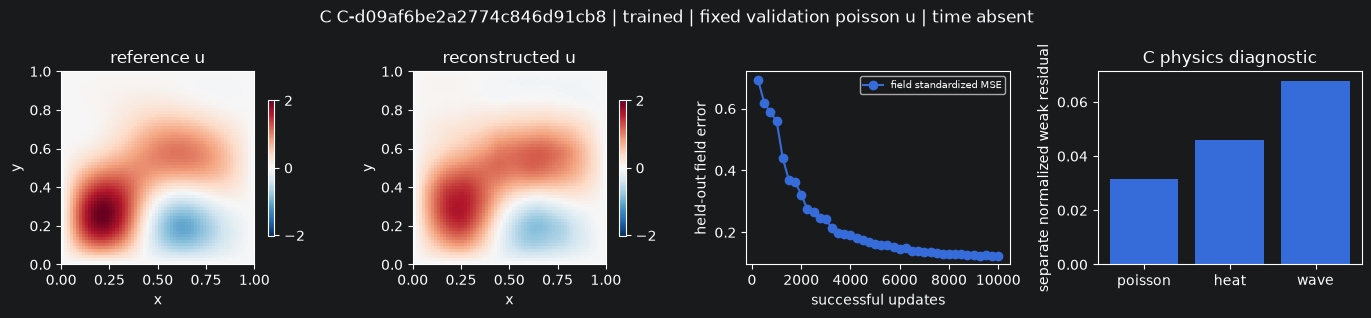

In [9]:
# RUN_MODE = "train"  # ONE deliberate start action after reviewing PLAN
from pdeep.notebook_workflows import launch_training,assert_plan_settings
# Stale source and changed checkpoint/destination settings are checked before launch.
assert_plan_settings(PLAN,**training_settings())
TRAINING_RESULTS = launch_training(PLAN,run_mode=RUN_MODE,models=MODELS_READY,notebook=True)
if RUN_MODE=="preview": print("PREVIEW ONLY: zero optimizer updates. Set RUN_MODE='train' in this cell to start.")


In [17]:
if not TRAINING_RESULTS:
    print("No training run launched.")
else:
    for name,result in TRAINING_RESULTS.items():
        engine=result["engine"]
        print(name,"run",engine.state.run_id,"| successful",engine.state.successful,"/",engine.config.updates,
              "| attempted",engine.state.attempted,"| skipped",engine.state.skipped,"| failed",engine.state.failed,
              "| interrupted",result["interrupted"])
        print("Fixed validation:",None if engine.latest_validation is None else engine.latest_validation.metrics["common"])
        print("Raw objectives are architecture-specific; use common held-out metrics for model comparison.")


No training run launched.


In [18]:
for name,result in TRAINING_RESULTS.items():
    engine=result["engine"]
    print(name,"last local resumable checkpoint:",result["last_checkpoint"])
    print("Best-validation checkpoint:",engine.state.best_checkpoint)
    print("Local inference export:",result["inference_export"])
    print("Structured histories:",engine.run_dir)
    print("Local save / Drive sync:",engine.state.persistence)
    print("Last verified Drive checkpoint:",engine.state.persistence.get("last_verified_Drive_checkpoint","none"))
    from pdeep.workflow_plotting import persistence_warning
    warning=persistence_warning(engine.state)
    if warning: display(Markdown("**"+warning+"**"))
print("Save and verified Drive copy run at every SAVE_EVERY checkpoint and new-best validation boundary, not only at the end.")
print("Drive checkpoint storage:",None if not SETUP["drive_root"] else Path(SETUP["drive_root"])/"checkpoints")


Save and verified Drive copy run at every SAVE_EVERY checkpoint and new-best validation boundary, not only at the end.
Drive checkpoint storage: None


In [11]:
# Optional final view; the same view was updated live after validation.
SHOW_FINAL_VALIDATION = True
if SHOW_FINAL_VALIDATION:
    from pdeep.workflow_plotting import plot_training_validation
    import matplotlib.pyplot as plt
    for result in TRAINING_RESULTS.values():
        if result["engine"].latest_validation is not None:
            fig=plot_training_validation(result["engine"]);display(fig);plt.close(fig)


## Resume after a disconnect
Open this notebook from GitHub again and run the two setup cells with the same repository commit/tag and Drive root. Select the same architecture (`B0` or `B1`, for example), set `ACTION="resume"` and `RESUME_CHECKPOINT` to a verified **Drive manifest** under `DRIVE_ROOT/checkpoints/<run_id>/<artifact_id>/update-XXXXXXXX.json`. Keep its payload beside it. Use the last **verified Drive** path printed by the monitor; a failed copy does not preserve the latest local update after Colab disconnects. You may browse Drive in Colab's Files panel to choose a completed manifest.

Rerun config, preview and model construction, then set `RUN_MODE="resume"` in Start training. Files are checksum-verified and copied into local storage before the existing loader restores model, Adam, scheduler, RNG, data ordering and counters. Preview checks scientific/architecture/configuration compatibility. Saved budget/device are preserved; a completed run does not restart. CPU/MPS checkpoints cannot implicitly migrate to CUDA. For suites provide one path per architecture.

**Local outputs:** `<installed project>/artifacts/training_runs/`. **Colab local outputs:** `LOCAL_OUTPUT_DIR/training_runs/`. **Drive:** `DRIVE_ROOT/checkpoints/`. Copies are verified at every checkpoint save. Local save and Drive sync have distinct states; a Drive failure leaves the local checkpoint intact and displays an alert. Inference exports are local unless explicitly persisted separately; the complete Drive training checkpoint can restore/export the model.

Use **03_evaluate.ipynb** for matched evaluation. Real Colab/CUDA/Drive verification requires a hosted runtime; local/mock tests do not establish hosted integration. Advanced setup is collapsed above; normal use needs only setup configuration, training configuration, preview and explicit launch.
